# FLC genome-wide — where the variant sits in the GEA

**The variant:** Chr5:3,175,803, a **6 bp deletion in the first intron of FLC**
(AT5G10140, FLOWERING LOCUS C -- the vernalization repressor), 28 carriers of the 78 founders called
here (34% call rate). Significant on **bio6 alone** (minimum temperature of the coldest month,
lambda 1.80), -log10 p = 7.81 against a 7.02 threshold -- a margin of 0.79.

FLC is in the candidate pool but in **no review table and no shortlist**: the gated GEA line requires
recurrence over >= 2 climate clusters, and this is one cluster. It is here because the pathway
around it keeps recurring (FRL2, FRL4B, HULK2, DFC, AGL100), not because the single record is strong.

Note the first intron is where the known functional FLC variation sits, which makes the position
interesting and the evidence no stronger.

**Layout** (as in `peak_alignment_manhattan_gea.ipynb`): **indels point up, SNPs point down** on one
genome axis; dashed lines are each class's own Bonferroni (0.05 / n records of that class); SNPs with
p > 0.01 are not drawn. Open red circles = indel peaks with no significant SNP within
10 kb. **The FLC variant is the filled red diamond**, with a vertical guide through
both halves.

The `up` class here is **smallindel**, the scan this variant's record actually lives in.

Per axis: the genome-wide figure, then a ±250 kb zoom on the locus, where the SNPs that track
the same haplotype are visible.

Raw LFMM p, gen9, MAF > 0.05, **no inflation correction** — these are a candidate net, not a
calibrated test.

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
def _tree_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while d != os.path.dirname(d):
        if os.path.basename(d) == "grenenet_selection" and os.path.exists(os.path.join(d, "lib.py")):
            return d
        d = os.path.dirname(d)
    raise RuntimeError("no grenenet_selection root above " + os.getcwd())
GS = _tree_root()
sys.path.insert(0, GS); sys.path.insert(0, f"{GS}/blocks"); sys.path.insert(0, f"{GS}/genes/convergence")
import lib, blocks_tiling as bt, plot_theme as TH
TH.apply()
WZAIN = f"{GS}/r2_gea_nonsnp/phase1_replication/results/multiaxis/wza_in_clq09_tile"
PLOTS = f"{GS}/notebooks/plots"; os.makedirs(PLOTS, exist_ok=True)
WINDOW, ZOOM_KB, SNP_FLOOR = 10000, 250, 2.0

# the candidate
GENE, SYM = "AT5G10140", "FLC"
VCHROM, VPOS, VSIZE = "Chr5", 3175803, 6
GSTART, GEND = 3173497, 3179448
UPCLS, UPLABEL, KIND = "smallindel", "indel", "6 bp intron deletion"

CHROM_LEN = {"Chr1": 30427671, "Chr2": 19698289, "Chr3": 23459830, "Chr4": 18585056, "Chr5": 26975502}
GAP = 3_500_000
CH = list(CHROM_LEN); OFF = {}; _a = 0
for _c in CH: OFF[_c] = _a; _a += CHROM_LEN[_c] + GAP
GENOME = _a - GAP
VX = OFF[VCHROM] + VPOS

SVCOL, SVLIGHT = "#3F7D4A", "#8DB896"
SNPCOL = ("#8A8A8A", "#C4C4C4")
AXISNAME = {"pc1": "climate PC1", "bio1": "annual mean temperature",
            "bio3": "isothermality", "bio6": "min temperature of coldest month",
            "bio11": "mean temperature of coldest quarter", "bio12": "annual precipitation",
            "bio15": "precipitation seasonality", "bio14": "precipitation of driest month",
            "bio17": "precipitation of driest quarter", "bio8": "mean temp of wettest quarter",
            "bio9": "mean temp of driest quarter"}

def load(cls, axis):
    d = pd.read_csv(f"{WZAIN}/lfmm_{cls}_gen9_{axis}.csv", usecols=["chrom", "pos", "MAF", "pval"])
    d = d[d.MAF > 0.05].copy()
    d["block"] = bt.assign_tiling(d.chrom.to_numpy(), d.pos.to_numpy(), r2=0.9)
    d["nlp"] = -np.log10(d.pval.clip(lower=1e-300))
    d["x"] = d.chrom.map(OFF) + d.pos
    d.attrs["bar"] = -np.log10(0.05 / len(d))
    return d

def sv_snp_peaks(D, window):
    # significant blocks per class -> record-span extents -> merged within `window` -> SV peaks,
    # flagged sv_only when the peak carries no significant SNP (the rule of the main notebook)
    rows = []
    for cls in [UPCLS, "snp"]:
        d = D[cls]; lead = d.groupby("block").nlp.max(); sb = set(lead.index[lead > d.attrs["bar"]])
        e = d[d.block.isin(sb)].groupby("block").agg(chrom=("chrom", "first"), start=("pos", "min"),
                                                     end=("pos", "max")).reset_index()
        e["cls"] = cls; rows.append(e)
    t = pd.concat(rows).sort_values(["chrom", "start"])
    lid, cur, pch, pend = [], -1, None, -np.inf
    for r in t.itertuples():
        if r.chrom != pch or r.start - pend > window: cur += 1; pend = r.end
        else: pend = max(pend, r.end)
        pch = r.chrom; lid.append(cur)
    t["locus"] = lid
    out = []
    for lid, g in t.groupby("locus"):
        ch, lo, hi = g.chrom.iloc[0], g.start.min(), g.end.max()
        if UPCLS not in set(g.cls): continue
        q = D[UPCLS][(D[UPCLS].chrom == ch) & D[UPCLS].pos.between(lo, hi)]
        b = q.loc[q.nlp.idxmax()]
        out.append(dict(chrom=ch, start=lo, end=hi, pos=int(b.pos), x=int(b.x), nlp=float(b.nlp),
                        sv_only="snp" not in set(g.cls)))
    return pd.DataFrame(out)

def cand_record(D):
    # the variant's own -log10 p per class on this axis (NaN if the record is absent)
    out = {}
    for cls in [UPCLS, "nonsnp", "snp"]:
        q = D[cls][(D[cls].chrom == VCHROM) & (D[cls].pos == VPOS)]
        out[cls] = float(q.nlp.max()) if len(q) else np.nan
    return out

print("loaded helpers ·", SYM, f"{VCHROM}:{VPOS:,} ({KIND})")

loaded helpers · FLC Chr5:3,175,803 (6 bp intron deletion)


In [2]:
def manh(ax, d, cols, sign=1, s=1.6, alt=True):
    for i, ch in enumerate(CH):
        k = d[d.chrom == ch]
        if len(k):
            ax.scatter(k.x, sign * k.nlp, s=s, c=cols[i % 2] if alt else cols[0],
                       linewidths=0, rasterized=True, zorder=1)

def cand_mark(ax, nlp_sv, shift, lo, hi, label=True):
    # vertical guide through both halves + a filled diamond on the deletion's SV point
    if not (lo <= VX <= hi): return
    ax.axvline(VX, color=TH.ACCENT, lw=1.0, ls=(0, (4, 3)), alpha=0.55, zorder=2)
    if np.isfinite(nlp_sv):
        ax.scatter([VX], [nlp_sv], marker="D", s=70, color=TH.ACCENT, edgecolor="white",
                   linewidth=0.8, zorder=7, clip_on=False)
    if label:
        ax.annotate(f"{SYM}\n{VCHROM}:{VPOS:,}", (VX, ax.get_ylim()[1]), xytext=(6, -4),
                    textcoords="offset points", ha="left", va="top", fontsize=8.5, color=TH.ACCENT)

def miami(axis, D, P, lo=0, hi=None, zoom=False, fname=None):
    hi = GENOME if hi is None else hi
    fig, ax = plt.subplots(figsize=(17, 6.2 if not zoom else 5.4))
    sv = D[UPCLS]; snp = D["snp"]
    inx = lambda d: d[(d.x >= lo) & (d.x <= hi)]
    SHIFT = SNP_FLOOR - 0.5 if not zoom else 0.0        # the p>0.01 cut only applies genome-wide
    s = inx(snp) if zoom else inx(snp[snp.nlp >= SNP_FLOOR]).assign(nlp=lambda d: d.nlp - SHIFT)
    manh(ax, inx(sv), (SVCOL, SVLIGHT), +1, s=3 if zoom else 1.6, alt=not zoom)
    manh(ax, s, SNPCOL, -1, s=3 if zoom else 1.6, alt=not zoom)
    ax.axhline(sv.attrs["bar"], ls="--", lw=0.8, color=TH.MUTED)
    ax.axhline(-(snp.attrs["bar"] - SHIFT), ls="--", lw=0.8, color=TH.MUTED)
    ax.axhline(0, color=TH.AXIS, lw=0.8)
    if not zoom:
        q = P[P.sv_only]
        ax.scatter(q.x, q.nlp, s=110, facecolor="none", edgecolor="#B03A4B", linewidth=1.3,
                   alpha=0.55, zorder=5, clip_on=False)
    top = max(inx(sv).nlp.max(), 1) * 1.18
    bot = max(inx(snp).nlp.max() - SHIFT, 1) * 1.10
    ax.set_ylim(-bot, top)
    up = np.arange(0, top, 2 if zoom else 4)
    dn = np.arange(2 if zoom else 4, inx(snp).nlp.max() + 1, 2 if zoom else 4)
    ax.set_yticks(np.r_[-(dn[::-1] - SHIFT), up])
    ax.set_yticklabels([f"{v:g}" for v in dn[::-1]] + [f"{v:g}" for v in up])
    ax.set_ylabel(f"−log10 p\nSNP ↓        {UPLABEL} ↑")
    TH.grid_only(ax, "y")
    cand_mark(ax, cand_record(D)[UPCLS], SHIFT, lo, hi)
    if zoom:
        ax.axvspan(OFF[VCHROM] + GSTART, OFF[VCHROM] + GEND, color=TH.ACCENT, alpha=0.10, lw=0, zorder=0)
        # ticks on round 50 kb positions, not on the window edges (which round to the wrong label)
        step = 50_000
        t0 = int(np.ceil((lo - OFF[VCHROM]) / step) * step)
        tk = np.arange(t0, hi - OFF[VCHROM], step)
        ax.set_xticks(OFF[VCHROM] + tk); ax.set_xticklabels([f"{t/1e6:.2f}" for t in tk], fontsize=8.5)
        ax.set_xlabel(f"{VCHROM} position (Mb)")
        ax.set_xlim(lo, hi)
    else:
        pad = 0.015 * GENOME
        ax.set_xlim(-pad, GENOME + pad)
        ax.set_xticks([OFF[c] + CHROM_LEN[c] / 2 for c in CH]); ax.set_xticklabels(CH, fontsize=11)
        ax.tick_params(axis="x", length=0)
    h = [Line2D([], [], marker="D", ls="", color=TH.ACCENT, markersize=8,
                label=f"{SYM} {KIND}")]
    if not zoom:
        h.append(Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor="#B03A4B",
                        markeredgewidth=1.3, markersize=10, alpha=0.7,
                        label=f"new {UPLABEL} peak"))
    h.append(Line2D([], [], ls="--", color=TH.MUTED, label="Bonferroni"))
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 0.9), ncol=len(h), fontsize=9.5)
    if fname:
        for ext in ["png", "pdf"]:
            plt.savefig(f"{PLOTS}/{fname}.{ext}", dpi=200, bbox_inches="tight", pad_inches=0.25)
    plt.show()

def run(axis):
    D = {c: load(c, axis) for c in ["snp", UPCLS]}
    if "nonsnp" not in D:
        D["nonsnp"] = load("nonsnp", axis)
    P = sv_snp_peaks(D, WINDOW)
    g = cand_record(D)
    rank = int((D[UPCLS].nlp > g[UPCLS]).sum() + 1) if np.isfinite(g[UPCLS]) else -1
    print(f"{axis} ({AXISNAME.get(axis, '')}): {SYM} {KIND} −log10 p = "
          f"{g[UPCLS]:.2f} ({UPCLS}), {g['nonsnp']:.2f} (non-SNP pool); {UPCLS} bar "
          f"{D[UPCLS].attrs['bar']:.2f}, SNP bar {D['snp'].attrs['bar']:.2f}; rank {rank} of "
          f"{len(D[UPCLS]):,} {UPCLS} records genome-wide; {len(P)} {UPLABEL} peaks, "
          f"{P.sv_only.sum()} with no significant SNP within {WINDOW // 1000} kb")
    miami(axis, D, P, fname=f"flc_miami_{axis}")
    lo, hi = VX - ZOOM_KB * 1000, VX + ZOOM_KB * 1000
    miami(axis, D, P, lo, hi, zoom=True, fname=f"flc_zoom_{axis}")
    return D, P

## bio6

bio6 (min temperature of coldest month): FLC 6 bp intron deletion −log10 p = 7.79 (smallindel), 7.81 (non-SNP pool); smallindel bar 7.13, SNP bar 7.61; rank 72 of 676,203 smallindel records genome-wide; 40 indel peaks, 23 with no significant SNP within 10 kb


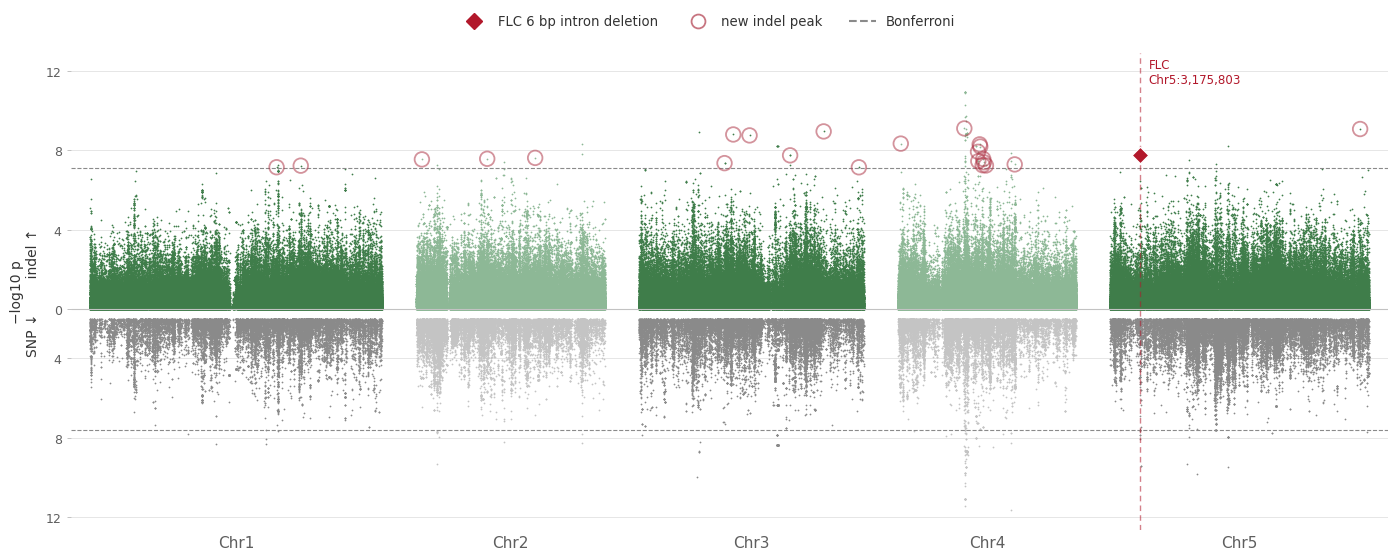

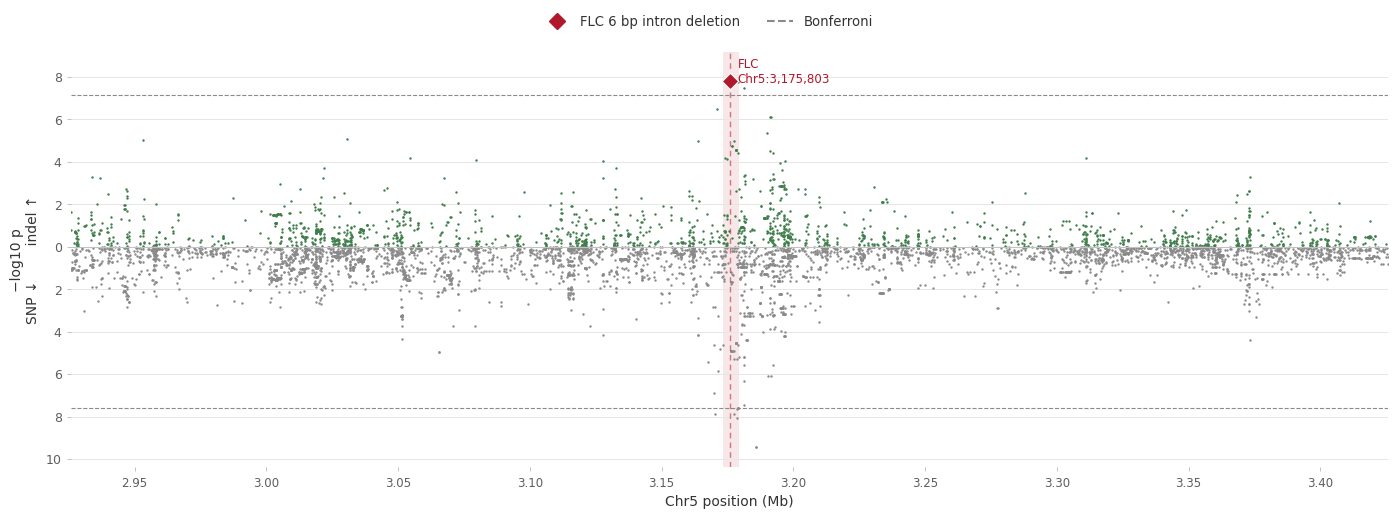

In [3]:
D, P = run("bio6")